# 1. Assignment Title

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Afnan-makstrix/comparative-machine-learning-regression/blob/main/comparative_ml_regression_colab.ipynb)

## Comparative Implementation of Machine Learning Regression Algorithms (Handwritten + Programming)

**Course:** Machine Learning / Artificial Intelligence  
**Degree:** Bachelor of Science in Artificial Intelligence (BS AI)  
**Author:** Muhammad Afnan  
**Dataset:** California Housing Dataset (Scikit-Learn)  
**Target:** `MedHouseVal` (Median House Value in $100,000s)  


In [1]:
!pip install -q xgboost scikit-learn pandas numpy matplotlib seaborn

import time
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.precision', 4)

os.makedirs('figures', exist_ok=True)



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# 2. Introduction

This study evaluates six supervised machine learning regression algorithms on the California Housing dataset:
1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression
4. Neural Network Regression (MLPRegressor)
5. XGBoost Regression (XGBRegressor)
6. K-Nearest Neighbors Regression (KNeighborsRegressor)

Evaluation is performed across multiple metrics: MAE, MSE, RMSE, R² Score, training time, and prediction latency.


# 3. Dataset Loading

The dataset consists of 20,640 records and 8 input features representing demographic and geographic indicators across California census blocks.


In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
feature_names = housing.feature_names
target_name = housing.target_names[0]

print("Shape:", df.shape)
print("Features:", feature_names)
print("Target:", target_name)


Shape: (20640, 9)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal


# 4. Dataset Exploration

Displaying sample records, schema info, and summary statistics.


In [3]:
display(df.head(5))


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.9841,1.0238,322.0,2.5556,37.88,-122.23,4.526
1,8.3014,21.0,6.2381,0.9719,2401.0,2.1098,37.86,-122.22,3.585
2,7.2574,52.0,8.2881,1.0734,496.0,2.8023,37.85,-122.24,3.521
3,5.6431,52.0,5.8174,1.0731,558.0,2.5479,37.85,-122.25,3.413
4,3.8462,52.0,6.2819,1.0811,565.0,2.1815,37.85,-122.25,3.422


In [4]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
display(df.describe().round(4))


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000,20640.0000
mean,3.8707,28.6395,5.4290,1.0967,1425.4767,3.0707,35.6319,-119.5697,2.0686
std,1.8998,12.5856,2.4742,0.4739,1132.4621,10.3860,2.1360,2.0035,1.1540
min,0.4999,1.0000,0.8462,0.3333,3.0000,0.6923,32.5400,-124.3500,0.1500
25%,2.5634,18.0000,4.4407,1.0061,787.0000,2.4297,33.9300,-121.8000,1.1960
50%,3.5348,29.0000,5.2291,1.0488,1166.0000,2.8181,34.2600,-118.4900,1.7970
75%,4.7432,37.0000,6.0524,1.0995,1725.0000,3.2823,37.7100,-118.0100,2.6472
max,15.0001,52.0000,141.9091,34.0667,35682.0000,1243.3333,41.9500,-114.3100,5.0000


# 5. Data Preprocessing

Checking data integrity and visualizing distributions, spatial patterns, and feature correlations.


In [6]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())


Missing values: 0
Duplicates: 0


### Graph 1: California Geographical House Value Distribution
Mapping census blocks by Latitude and Longitude, with bubble color representing median house value and bubble size proportional to block population.


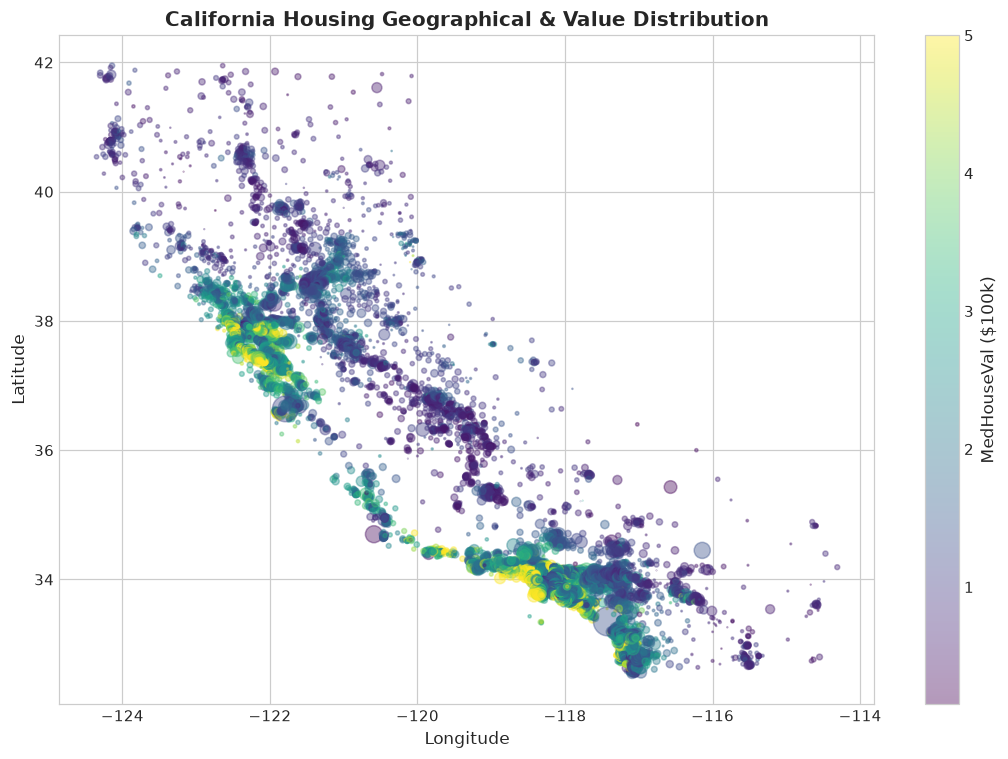

In [7]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df['Longitude'],
    df['Latitude'],
    c=df['MedHouseVal'],
    s=df['Population'] / 100,
    alpha=0.4,
    cmap='viridis'
)
cbar = plt.colorbar(scatter)
cbar.set_label('MedHouseVal ($100k)', fontsize=11)
plt.title('California Housing Geographical & Value Distribution', fontsize=13, fontweight='bold')
plt.xlabel('Longitude', fontsize=11)
plt.ylabel('Latitude', fontsize=11)
plt.tight_layout()
plt.savefig('figures/california_geo_distribution.png', dpi=300)
plt.show()


### Graph 2: Feature and Target Variable Distributions
Histograms with Kernel Density Estimation (KDE) overlays for all predictors and the target variable.


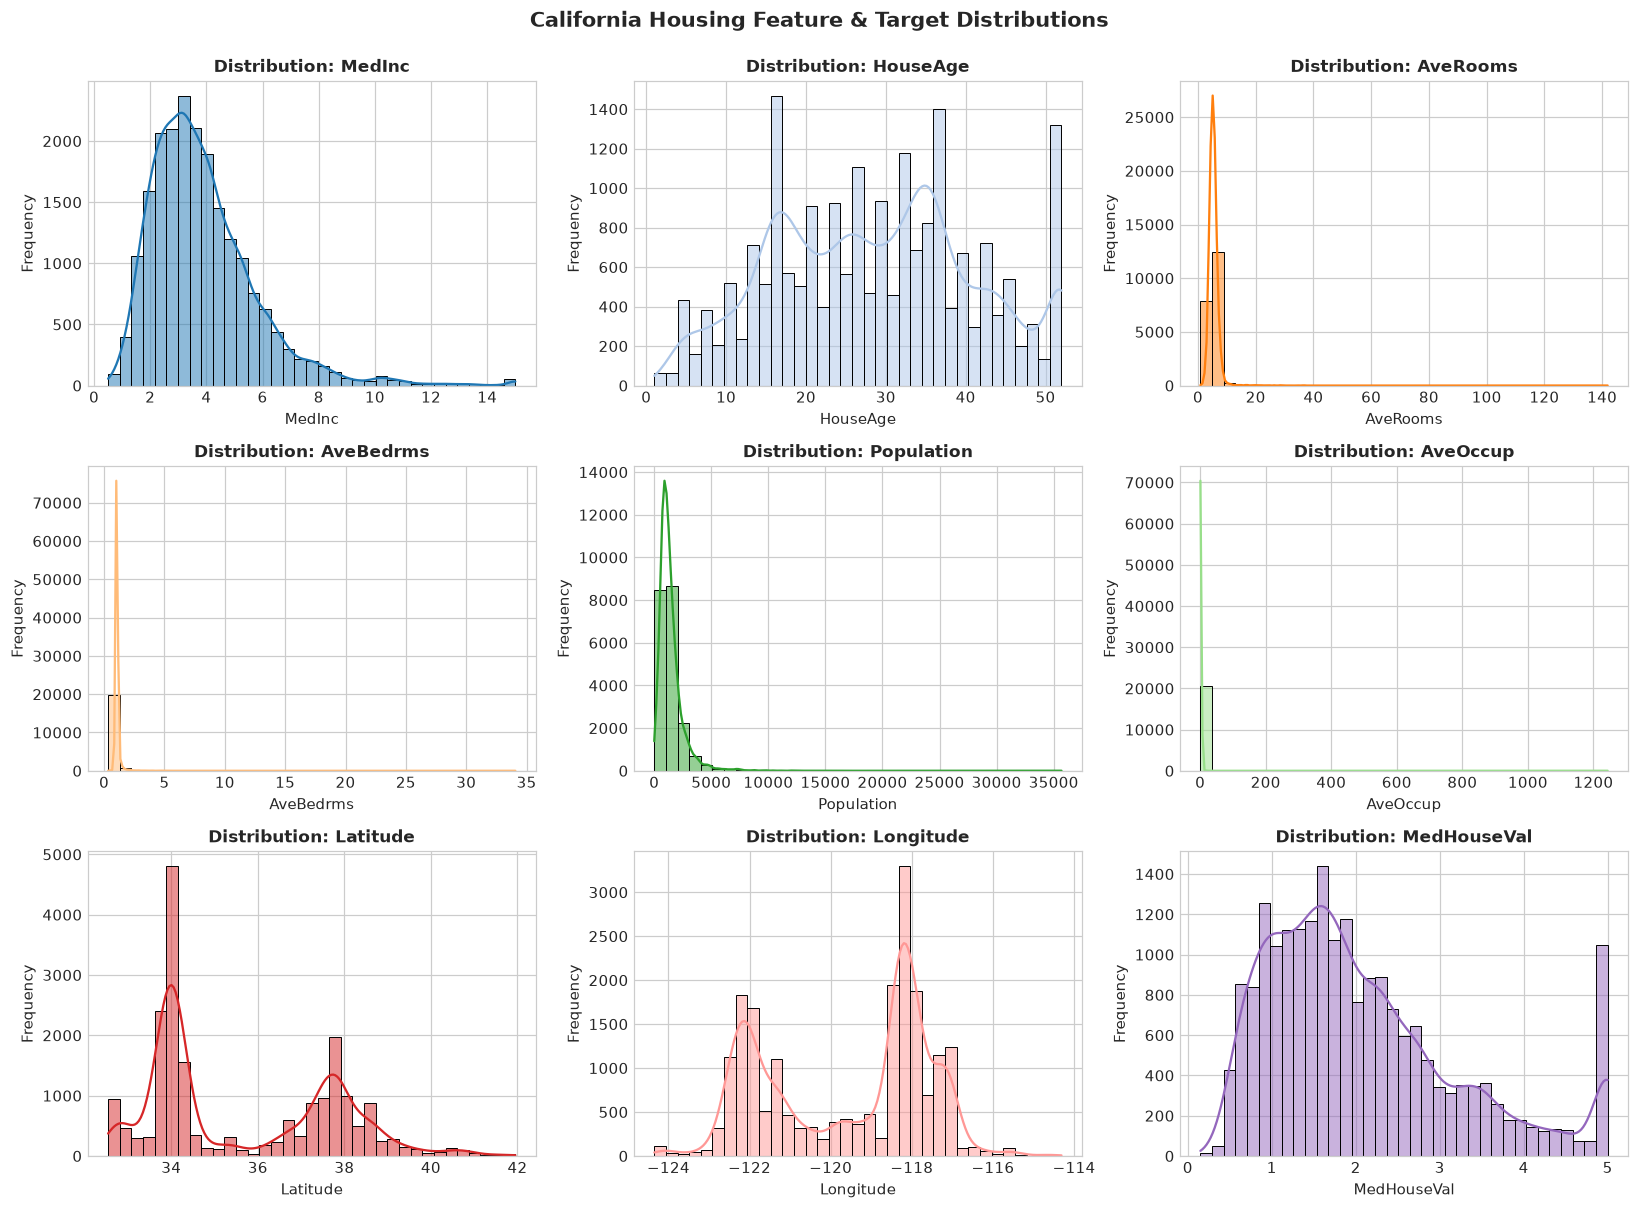

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()
all_cols = feature_names + [target_name]
colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#2ca02c', '#98df8a', '#d62728', '#ff9896', '#9467bd']

for i, col in enumerate(all_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i], bins=35)
    axes[i].set_title(f'Distribution: {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)

plt.suptitle('California Housing Feature & Target Distributions', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/feature_target_distributions.png', dpi=300)
plt.show()


### Graph 3: Pearson Correlation Matrix
Pairwise correlation coefficients across all 8 features and the target variable.


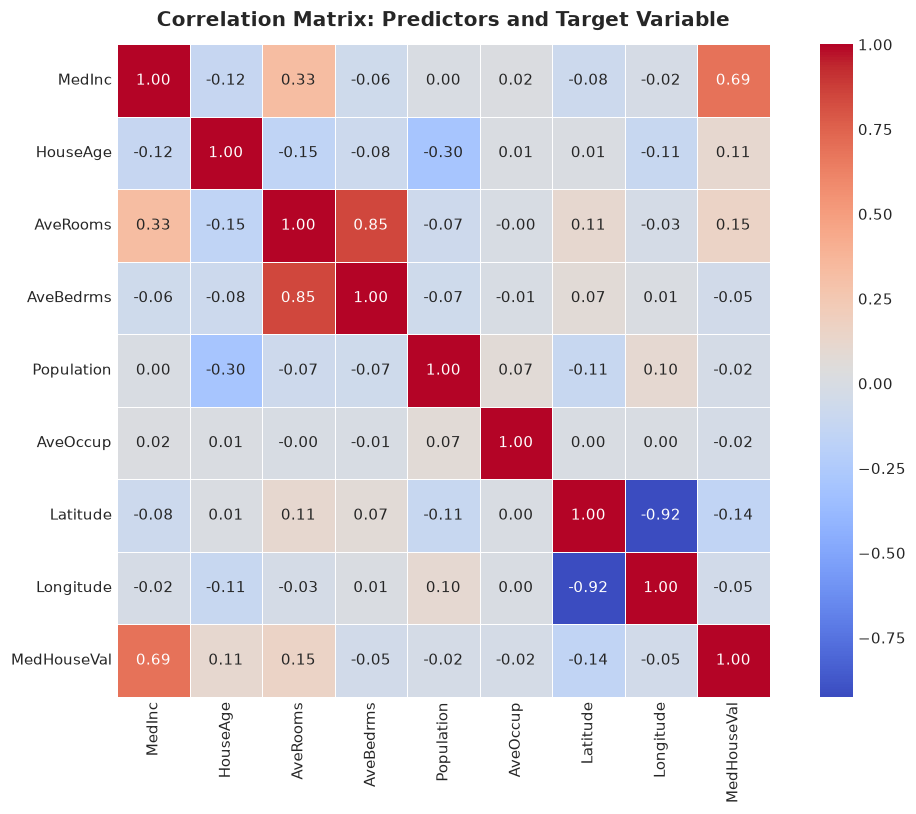

In [9]:
plt.figure(figsize=(10, 7.5))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Correlation Matrix: Predictors and Target Variable', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('figures/correlation_heatmap.png', dpi=300)
plt.show()


### Graph 4: Key Predictors vs. Target Value Relationships
Scatter plots with linear regression trendlines for the four most influential predictors.


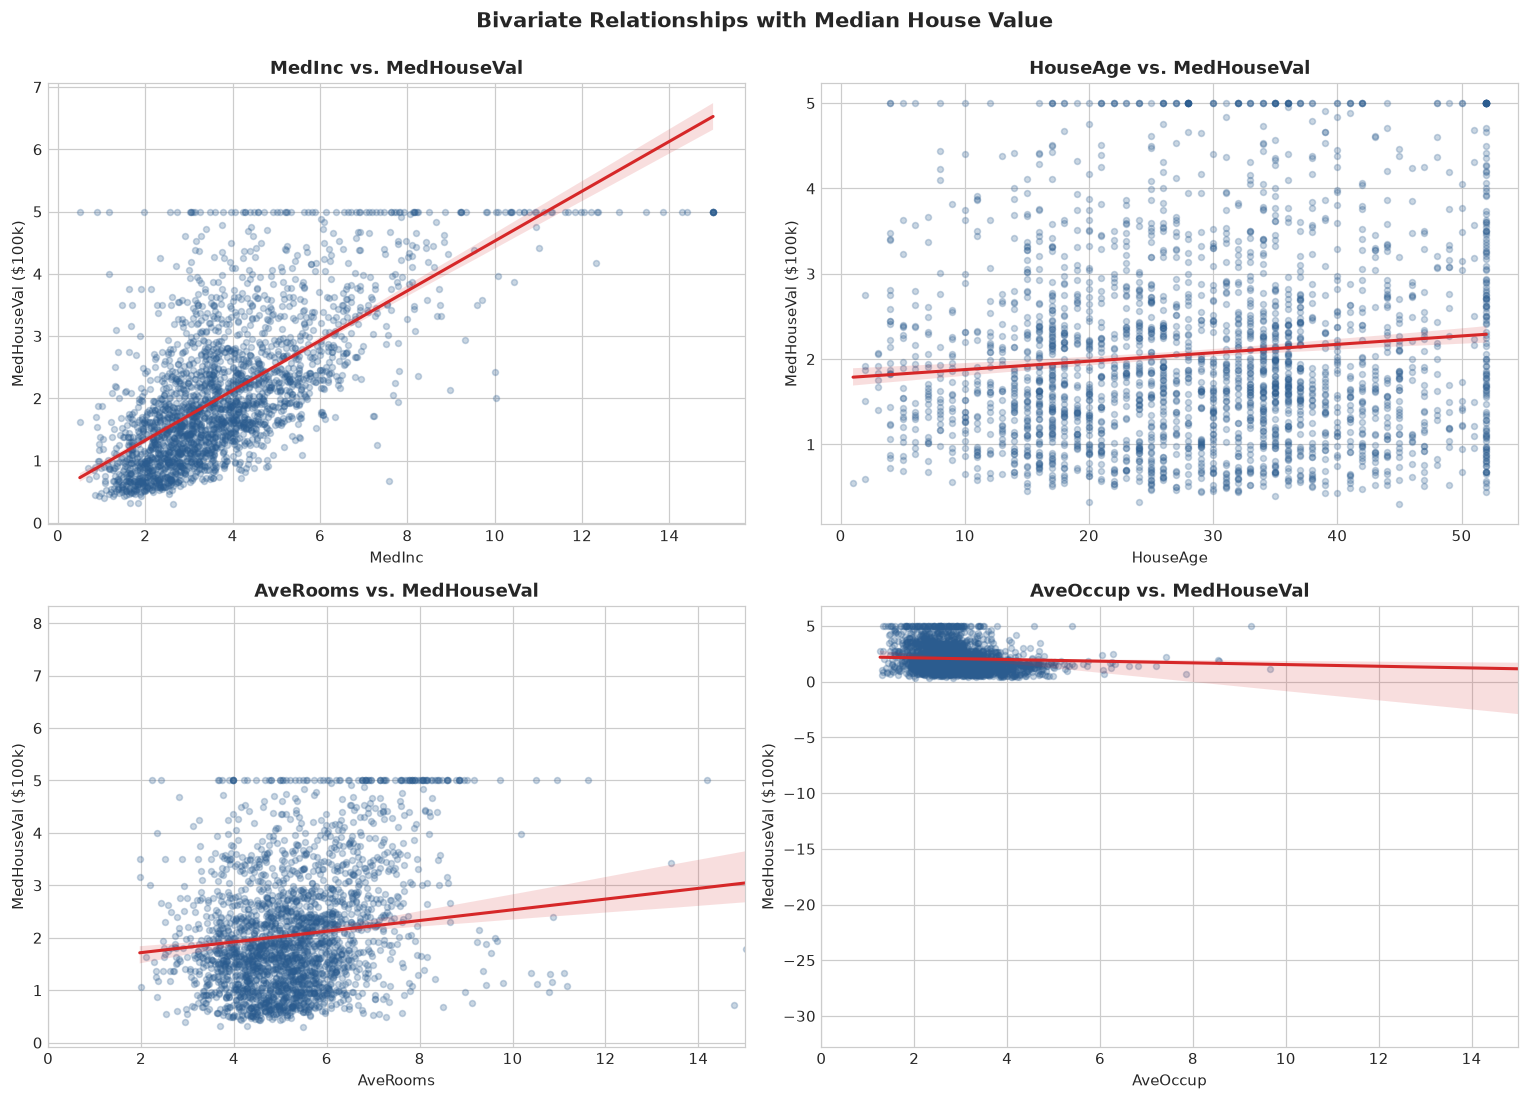

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
selected_features = ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup']

for i, feat in enumerate(selected_features):
    sample_df = df.sample(n=2500, random_state=42)
    sns.regplot(
        data=sample_df,
        x=feat,
        y='MedHouseVal',
        ax=axes[i],
        scatter_kws={'alpha': 0.25, 'color': '#2b5c8f', 's': 15},
        line_kws={'color': '#d62728', 'linewidth': 2}
    )
    axes[i].set_title(f'{feat} vs. MedHouseVal', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('MedHouseVal ($100k)', fontsize=10)
    axes[i].set_xlabel(feat, fontsize=10)
    if feat in ['AveRooms', 'AveOccup']:
        axes[i].set_xlim(0, 15)

plt.suptitle('Bivariate Relationships with Median House Value', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/bivariate_feature_target.png', dpi=300)
plt.show()


# 6. Train Test Split

Partitioning data into 80% training (16,512 samples) and 20% testing (4,128 samples) with `random_state=42`.


In [11]:
X = df.drop(columns=[target_name])
y = df[target_name]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)


X_train shape: (16512, 8)
X_test shape:  (4128, 8)


# 7. Feature Scaling

StandardScaler is fitted strictly on the training partition to prevent data leakage. Scaled features are routed to Linear Regression, Neural Network (MLP), and KNN. Tree-based models utilize original unscaled features.


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_registry = {}
predictions_store = {}
runtime_store = {}


# 8. Linear Regression

Ordinary Least Squares linear regression model.


In [13]:
lr_model = LinearRegression()

t_start = time.time()
lr_model.fit(X_train_scaled, y_train)
lr_train_time = time.time() - t_start

t_start = time.time()
lr_preds = lr_model.predict(X_test_scaled)
lr_pred_time = time.time() - t_start

model_registry['Linear Regression'] = lr_model
predictions_store['Linear Regression'] = lr_preds
runtime_store['Linear Regression'] = {'train_time': lr_train_time, 'pred_time': lr_pred_time}

print("Linear Regression trained.")
print(f"Train Time: {lr_train_time:.4f}s | Pred Time: {lr_pred_time:.4f}s")


Linear Regression trained.
Train Time: 0.0146s | Pred Time: 0.0000s


# 9. Decision Tree Regression

Recursive binary partitioning tree with `max_depth=10` and `random_state=42`.


In [14]:
dt_model = DecisionTreeRegressor(random_state=42, max_depth=10)

t_start = time.time()
dt_model.fit(X_train, y_train)
dt_train_time = time.time() - t_start

t_start = time.time()
dt_preds = dt_model.predict(X_test)
dt_pred_time = time.time() - t_start

model_registry['Decision Tree'] = dt_model
predictions_store['Decision Tree'] = dt_preds
runtime_store['Decision Tree'] = {'train_time': dt_train_time, 'pred_time': dt_pred_time}

print("Decision Tree trained.")
print(f"Train Time: {dt_train_time:.4f}s | Pred Time: {dt_pred_time:.4f}s")


Decision Tree trained.
Train Time: 0.0561s | Pred Time: 0.0020s


# 10. Random Forest Regression

Bootstrap aggregated ensemble of 100 decorrelated decision trees.


In [15]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

t_start = time.time()
rf_model.fit(X_train, y_train)
rf_train_time = time.time() - t_start

t_start = time.time()
rf_preds = rf_model.predict(X_test)
rf_pred_time = time.time() - t_start

model_registry['Random Forest'] = rf_model
predictions_store['Random Forest'] = rf_preds
runtime_store['Random Forest'] = {'train_time': rf_train_time, 'pred_time': rf_pred_time}

print("Random Forest trained.")
print(f"Train Time: {rf_train_time:.4f}s | Pred Time: {rf_pred_time:.4f}s")


Random Forest trained.
Train Time: 0.8764s | Pred Time: 0.0300s


# 11. Neural Network Regression

Multi-Layer Perceptron regressor with two hidden layers `(64, 32)` and early stopping.


In [16]:
mlp_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    max_iter=500,
    early_stopping=True,
    random_state=42
)

t_start = time.time()
mlp_model.fit(X_train_scaled, y_train)
mlp_train_time = time.time() - t_start

t_start = time.time()
mlp_preds = mlp_model.predict(X_test_scaled)
mlp_pred_time = time.time() - t_start

model_registry['Neural Network (MLP)'] = mlp_model
predictions_store['Neural Network (MLP)'] = mlp_preds
runtime_store['Neural Network (MLP)'] = {'train_time': mlp_train_time, 'pred_time': mlp_pred_time}

print("Neural Network (MLP) trained.")
print(f"Train Time: {mlp_train_time:.4f}s | Pred Time: {mlp_pred_time:.4f}s")
print(f"Epochs Completed: {mlp_model.n_iter_}")


Neural Network (MLP) trained.
Train Time: 2.3170s | Pred Time: 0.0020s
Epochs Completed: 93


# 12. XGBoost Regression

Extreme Gradient Boosting regressor optimizing second-order Taylor expansion loss.


In [17]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42
)

t_start = time.time()
xgb_model.fit(X_train, y_train)
xgb_train_time = time.time() - t_start

t_start = time.time()
xgb_preds = xgb_model.predict(X_test)
xgb_pred_time = time.time() - t_start

model_registry['XGBoost'] = xgb_model
predictions_store['XGBoost'] = xgb_preds
runtime_store['XGBoost'] = {'train_time': xgb_train_time, 'pred_time': xgb_pred_time}

print("XGBoost trained.")
print(f"Train Time: {xgb_train_time:.4f}s | Pred Time: {xgb_pred_time:.4f}s")


XGBoost trained.
Train Time: 0.1126s | Pred Time: 0.0048s


# 13. KNN Regression

K-Nearest Neighbors regressor with $k=5$ evaluated over standardized Euclidean feature space.


In [18]:
knn_model = KNeighborsRegressor(n_neighbors=5)

t_start = time.time()
knn_model.fit(X_train_scaled, y_train)
knn_train_time = time.time() - t_start

t_start = time.time()
knn_preds = knn_model.predict(X_test_scaled)
knn_pred_time = time.time() - t_start

model_registry['KNN'] = knn_model
predictions_store['KNN'] = knn_preds
runtime_store['KNN'] = {'train_time': knn_train_time, 'pred_time': knn_pred_time}

print("KNN trained.")
print(f"Train Time: {knn_train_time:.4f}s | Pred Time: {knn_pred_time:.4f}s")


KNN trained.
Train Time: 0.0160s | Pred Time: 0.1027s


# 14. Model Evaluation

Computing MAE, MSE, RMSE, R² Score, and recording execution runtimes across all six models.


In [19]:
evaluation_records = []

for model_name, y_preds in predictions_store.items():
    mae = mean_absolute_error(y_test, y_preds)
    mse = mean_squared_error(y_test, y_preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_preds)
    t_train = runtime_store[model_name]['train_time']
    t_pred = runtime_store[model_name]['pred_time']
    
    evaluation_records.append({
        'Algorithm': model_name,
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'R² Score': round(r2, 4),
        'Train Time (s)': round(t_train, 4),
        'Pred Time (s)': round(t_pred, 4)
    })

eval_df = pd.DataFrame(evaluation_records)


# 15. Comparative Performance Table

Summary performance table sorted by RMSE ascending.


In [20]:
comparison_table = eval_df.sort_values(by="RMSE", ascending=True).reset_index(drop=True)
display(comparison_table)


,Algorithm,MAE,MSE,RMSE,R² Score,Train Time (s),Pred Time (s)
0,XGBoost,0.3155,0.2273,0.4767,0.8266,0.1126,0.0048
1,Random Forest,0.3277,0.2560,0.5060,0.8046,0.8764,0.0300
2,Neural Network (MLP),0.3533,0.2745,0.5239,0.7905,2.3170,0.0020
3,Decision Tree,0.4335,0.4165,0.6454,0.6822,0.0561,0.0020
4,KNN,0.4462,0.4324,0.6576,0.6700,0.0160,0.1027
5,Linear Regression,0.5332,0.5559,0.7456,0.5758,0.0146,0.0000


# 16. Visualizations

Extensive graphical diagnostics comparing predictions, residual behavior, error distributions, training/inference speeds, and feature importance.


### Graph 5: Actual vs. Predicted Values (2x3 Subplot Grid)
Comparing true target values against model predictions. The dashed red diagonal represents perfect predictions ($y = x$).


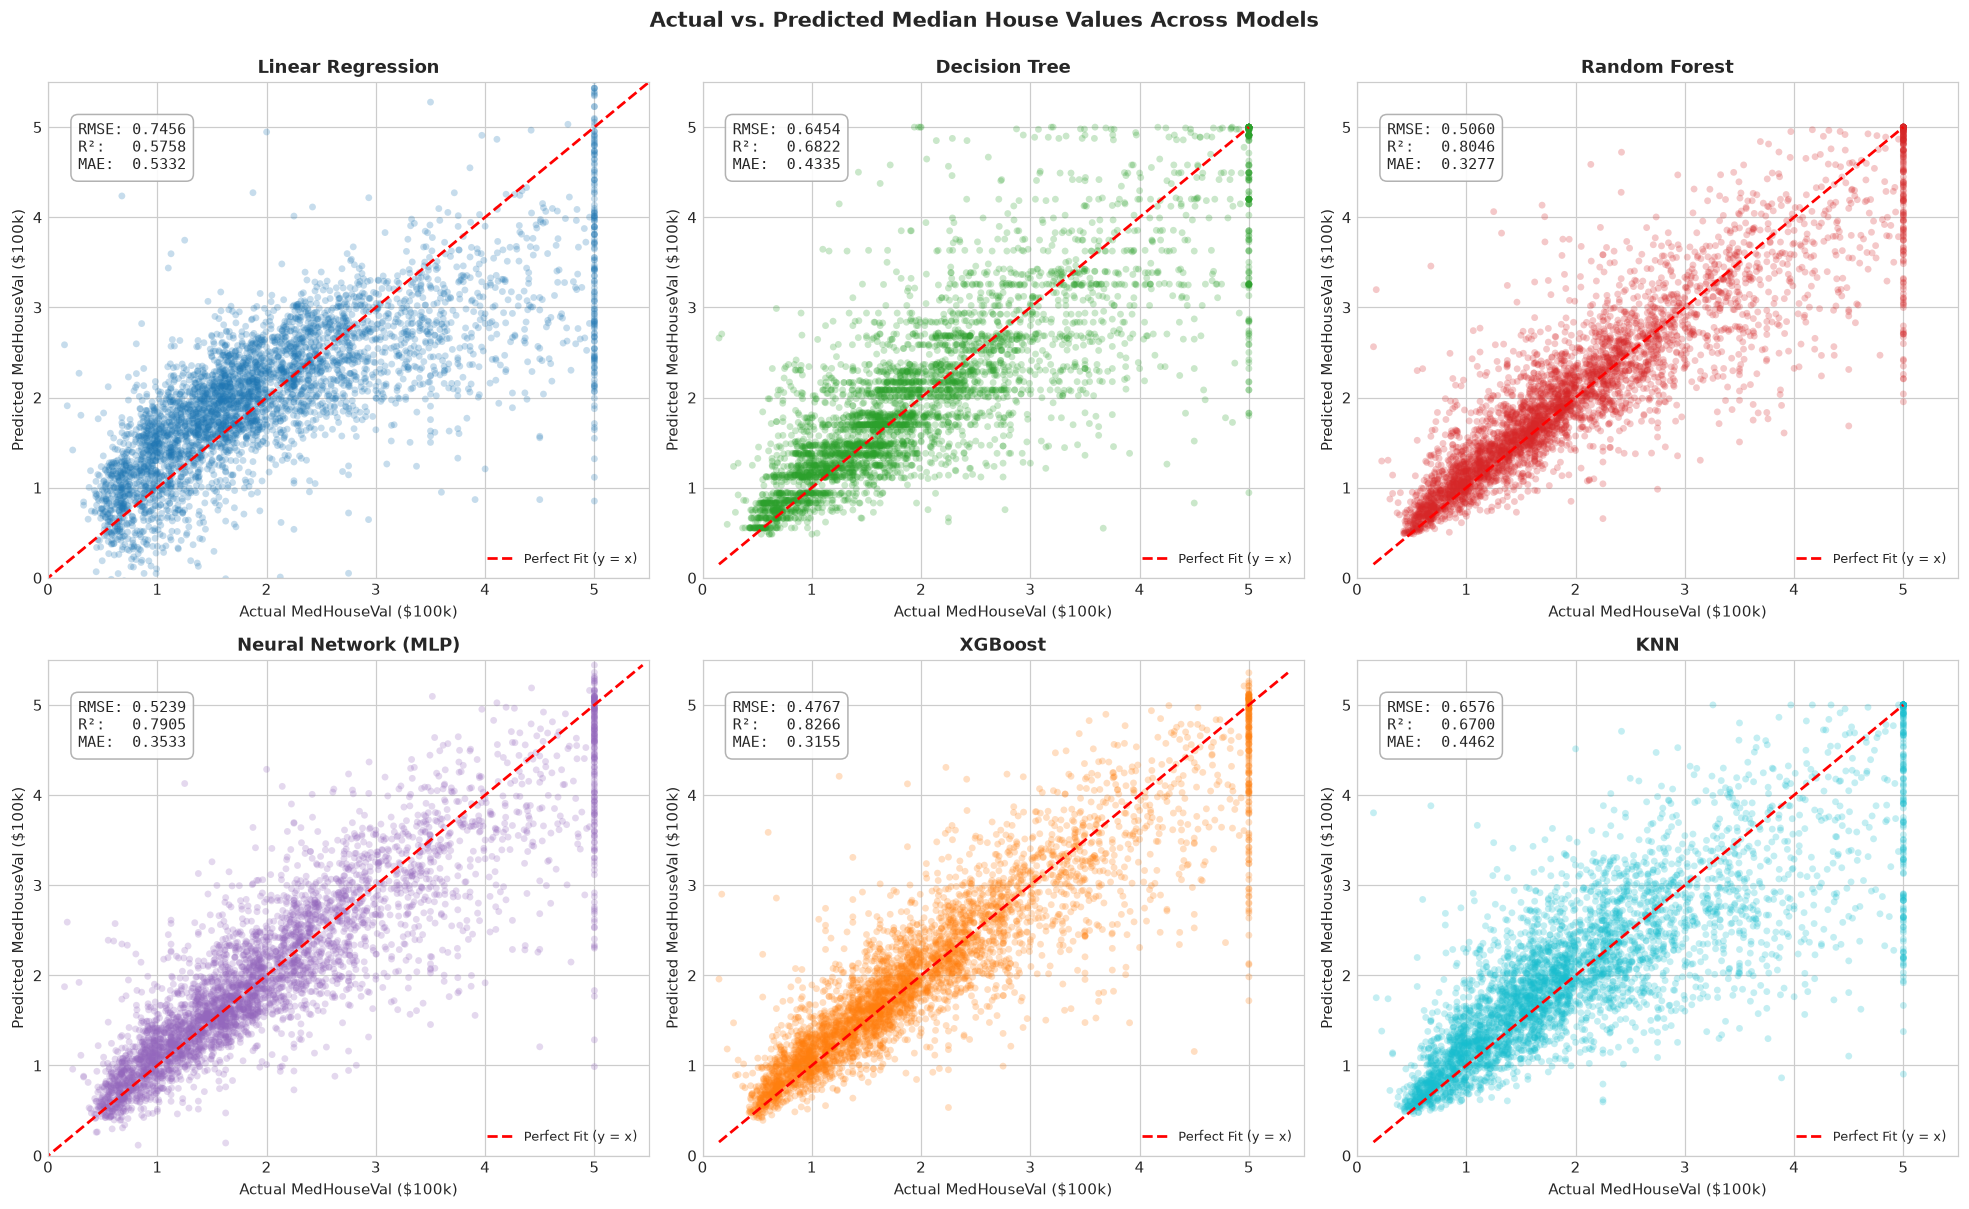

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

model_names = list(predictions_store.keys())
plot_colors = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#17becf']

for idx, model_name in enumerate(model_names):
    ax = axes[idx]
    preds = predictions_store[model_name]
    
    ax.scatter(y_test, preds, alpha=0.25, color=plot_colors[idx], edgecolors='none', s=20)
    
    min_bound = min(y_test.min(), preds.min())
    max_bound = max(y_test.max(), preds.max())
    ax.plot([min_bound, max_bound], [min_bound, max_bound], color='red', linestyle='--', linewidth=1.8, label='Perfect Fit (y = x)')
    
    row = comparison_table[comparison_table['Algorithm'] == model_name].iloc[0]
    metric_label = f"RMSE: {row['RMSE']:.4f}\nR²:   {row['R² Score']:.4f}\nMAE:  {row['MAE']:.4f}"
    ax.text(0.05, 0.92, metric_label, transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.90, edgecolor='#aaaaaa'),
            fontsize=9.5, family='monospace')
    
    ax.set_title(f"{model_name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Actual MedHouseVal ($100k)", fontsize=10)
    ax.set_ylabel("Predicted MedHouseVal ($100k)", fontsize=10)
    ax.set_xlim(0, 5.5)
    ax.set_ylim(0, 5.5)
    ax.legend(loc='lower right', fontsize=8.5)

plt.suptitle("Actual vs. Predicted Median House Values Across Models", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/actual_vs_predicted_subplots.png', dpi=300)
plt.show()


### Graph 6: Residuals vs. Predicted Values (Homoscedasticity Diagnostic)
Plotting residuals $(y - \hat{y})$ against predicted values $\hat{y}$ to detect heteroscedasticity or non-linear residual patterns. The red dashed line denotes zero residual error.


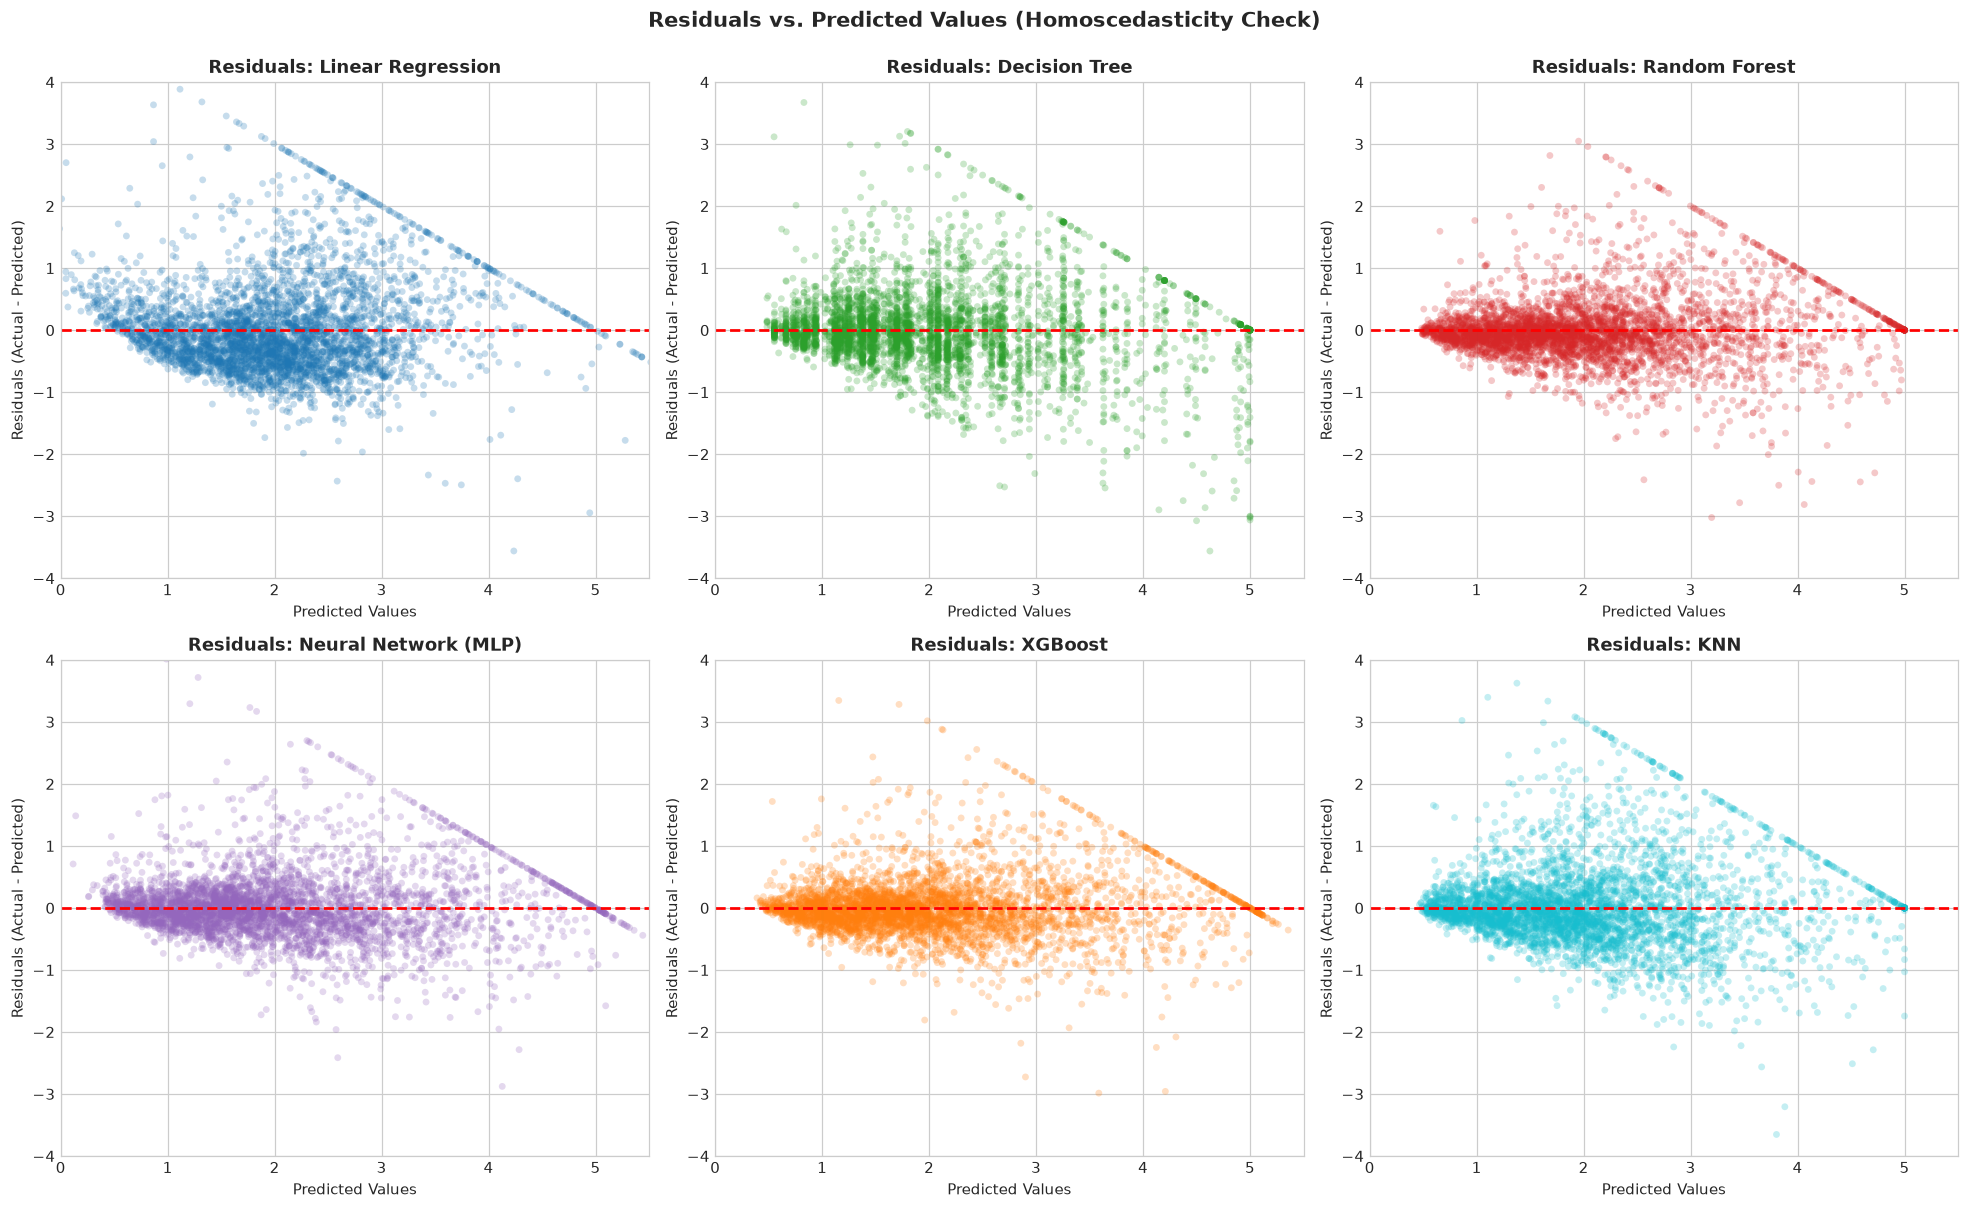

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, model_name in enumerate(model_names):
    ax = axes[idx]
    preds = predictions_store[model_name]
    residuals = y_test - preds
    
    ax.scatter(preds, residuals, alpha=0.25, color=plot_colors[idx], edgecolors='none', s=20)
    ax.axhline(0, color='red', linestyle='--', linewidth=1.8)
    
    ax.set_title(f"Residuals: {model_name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicted Values", fontsize=10)
    ax.set_ylabel("Residuals (Actual - Predicted)", fontsize=10)
    ax.set_xlim(0, 5.5)
    ax.set_ylim(-4, 4)

plt.suptitle("Residuals vs. Predicted Values (Homoscedasticity Check)", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/residuals_vs_predicted.png', dpi=300)
plt.show()


### Graph 7: Residual Error Distribution Histograms
Checking normality of residuals across all six algorithms. A bell-shaped curve centered at zero indicates unbiased estimation.


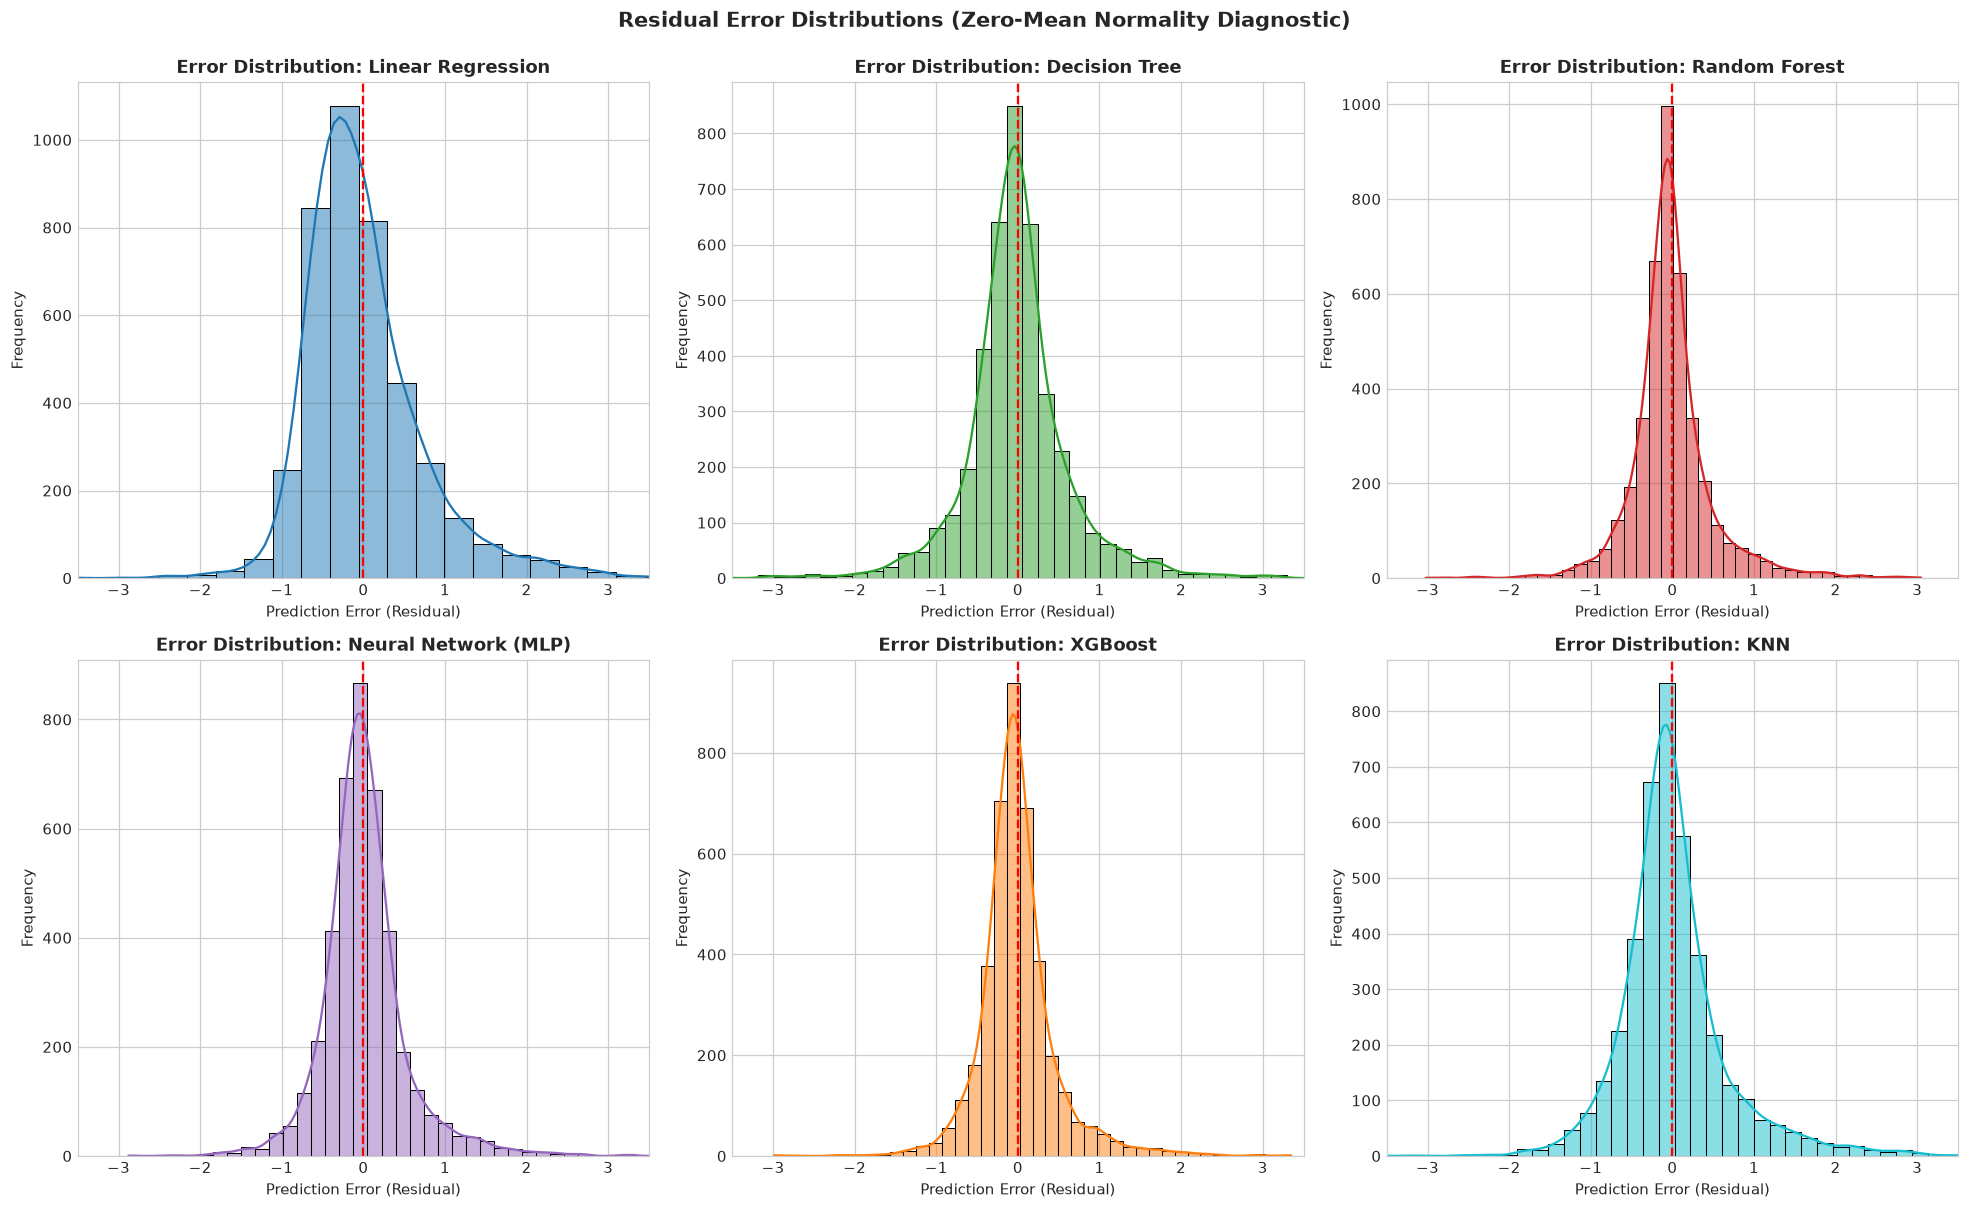

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, model_name in enumerate(model_names):
    ax = axes[idx]
    preds = predictions_store[model_name]
    residuals = y_test - preds
    
    sns.histplot(residuals, kde=True, ax=ax, color=plot_colors[idx], bins=40)
    ax.axvline(0, color='red', linestyle='--', linewidth=1.5)
    
    ax.set_title(f"Error Distribution: {model_name}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Prediction Error (Residual)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.set_xlim(-3.5, 3.5)

plt.suptitle("Residual Error Distributions (Zero-Mean Normality Diagnostic)", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/residual_distributions.png', dpi=300)
plt.show()


### Graph 8: Root Mean Squared Error (RMSE) Comparison
Lower RMSE values indicate higher predictive precision.


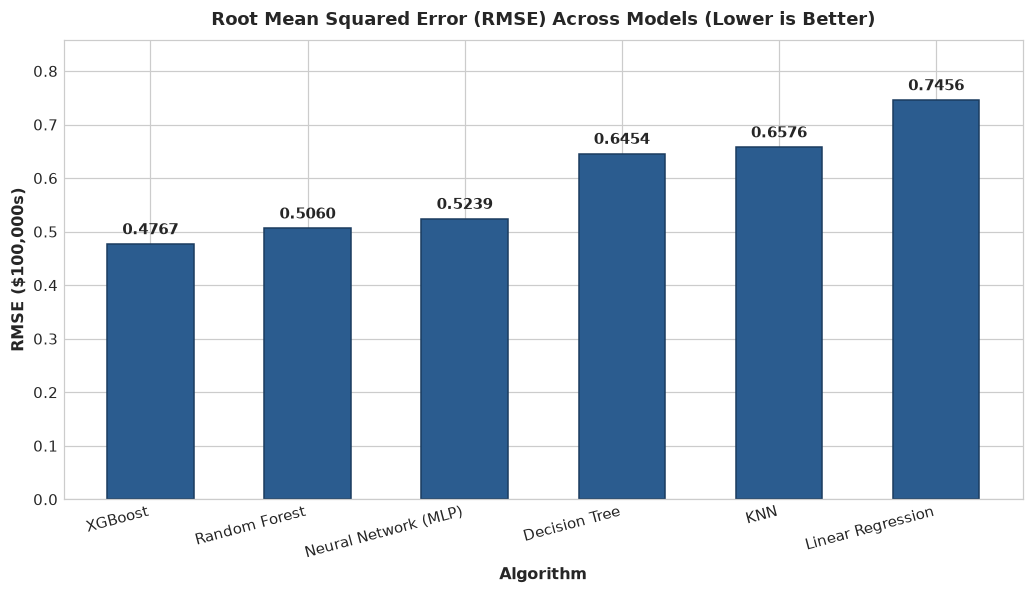

In [24]:
plt.figure(figsize=(9.5, 5.5))
sorted_by_rmse = comparison_table.sort_values(by="RMSE", ascending=True)
bars = plt.bar(sorted_by_rmse['Algorithm'], sorted_by_rmse['RMSE'], color='#2b5c8f', width=0.55, edgecolor='#1b3c5f')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 0.012, f'{height:.4f}',
             ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.title("Root Mean Squared Error (RMSE) Across Models (Lower is Better)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Algorithm", fontsize=10.5, fontweight='bold')
plt.ylabel("RMSE ($100,000s)", fontsize=10.5, fontweight='bold')
plt.ylim(0, sorted_by_rmse['RMSE'].max() * 1.15)
plt.xticks(rotation=15, ha='right', fontsize=9.5)
plt.tight_layout()
plt.savefig('figures/rmse_comparison_barchart.png', dpi=300)
plt.show()


### Graph 9: Mean Absolute Error (MAE) Comparison
Assessing average linear absolute prediction error across models.


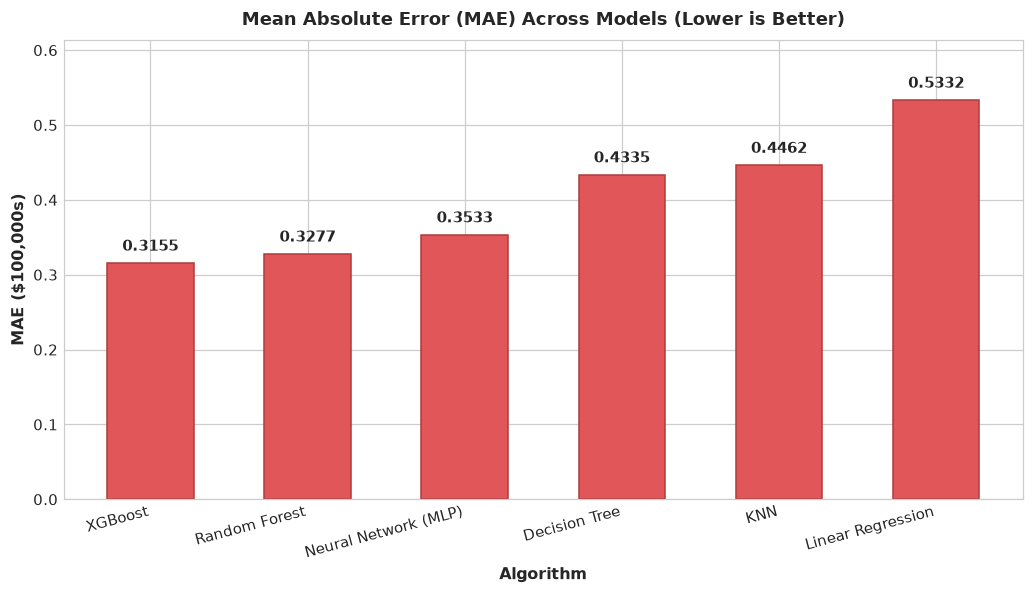

In [25]:
plt.figure(figsize=(9.5, 5.5))
sorted_by_mae = comparison_table.sort_values(by="MAE", ascending=True)
bars = plt.bar(sorted_by_mae['Algorithm'], sorted_by_mae['MAE'], color='#e15759', width=0.55, edgecolor='#b13a3c')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 0.012, f'{height:.4f}',
             ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.title("Mean Absolute Error (MAE) Across Models (Lower is Better)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Algorithm", fontsize=10.5, fontweight='bold')
plt.ylabel("MAE ($100,000s)", fontsize=10.5, fontweight='bold')
plt.ylim(0, sorted_by_mae['MAE'].max() * 1.15)
plt.xticks(rotation=15, ha='right', fontsize=9.5)
plt.tight_layout()
plt.savefig('figures/mae_comparison_barchart.png', dpi=300)
plt.show()


### Graph 10: R² Score Comparison
Proportion of target variance accounted for by each regression model.


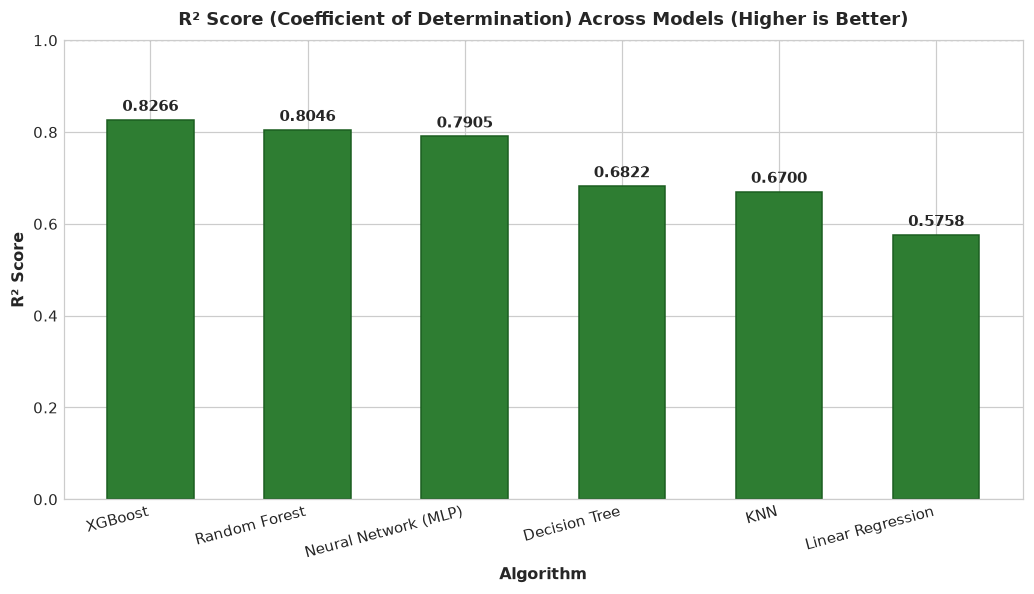

In [26]:
plt.figure(figsize=(9.5, 5.5))
sorted_by_r2 = comparison_table.sort_values(by="R² Score", ascending=False)
bars = plt.bar(sorted_by_r2['Algorithm'], sorted_by_r2['R² Score'], color='#2e7d32', width=0.55, edgecolor='#1b5e20')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 0.012, f'{height:.4f}',
             ha='center', va='bottom', fontsize=9.5, fontweight='bold')

plt.title("R² Score (Coefficient of Determination) Across Models (Higher is Better)", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Algorithm", fontsize=10.5, fontweight='bold')
plt.ylabel("R² Score", fontsize=10.5, fontweight='bold')
plt.ylim(0, 1.0)
plt.axhline(1.0, color='grey', linestyle=':', alpha=0.7)
plt.xticks(rotation=15, ha='right', fontsize=9.5)
plt.tight_layout()
plt.savefig('figures/r2_comparison_barchart.png', dpi=300)
plt.show()


### Graph 11: Multi-Metric Grouped Performance Comparison
Direct side-by-side view of MAE, MSE, RMSE, and R² Score.


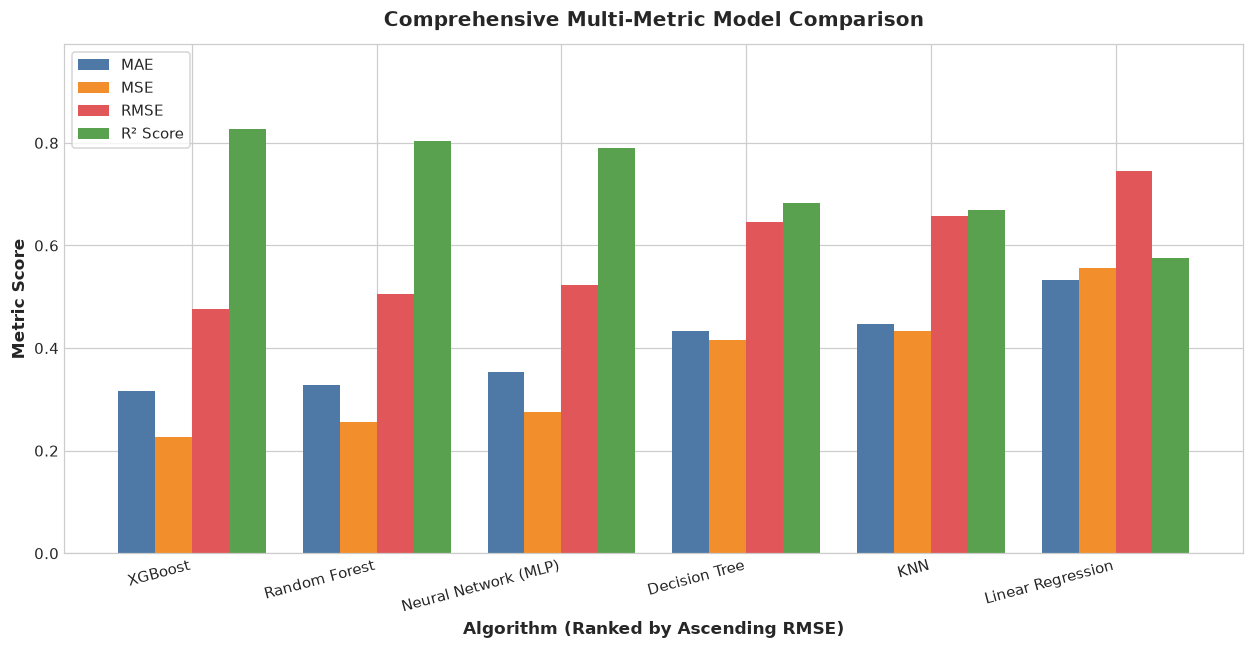

In [27]:
plt.figure(figsize=(11.5, 6))
indices = np.arange(len(comparison_table))
bar_width = 0.20

plt.bar(indices - bar_width * 1.5, comparison_table["MAE"], bar_width, label="MAE", color="#4e79a7")
plt.bar(indices - bar_width * 0.5, comparison_table["MSE"], bar_width, label="MSE", color="#f28e2b")
plt.bar(indices + bar_width * 0.5, comparison_table["RMSE"], bar_width, label="RMSE", color="#e15759")
plt.bar(indices + bar_width * 1.5, comparison_table["R² Score"], bar_width, label="R² Score", color="#59a14f")

plt.xlabel("Algorithm (Ranked by Ascending RMSE)", fontsize=11, fontweight='bold')
plt.ylabel("Metric Score", fontsize=11, fontweight='bold')
plt.title("Comprehensive Multi-Metric Model Comparison", fontsize=13, fontweight='bold', pad=12)
plt.xticks(indices, comparison_table["Algorithm"], rotation=15, ha='right', fontsize=9.5)
plt.legend(frameon=True, facecolor='white', loc='upper left', fontsize=10)
plt.ylim(0, max(comparison_table["RMSE"].max(), comparison_table["R² Score"].max()) * 1.20)
plt.tight_layout()
plt.savefig('figures/overall_model_comparison.png', dpi=300)
plt.show()


### Graph 12: Computational Efficiency Comparison
Contrasting wall-clock training times and test query inference latencies.


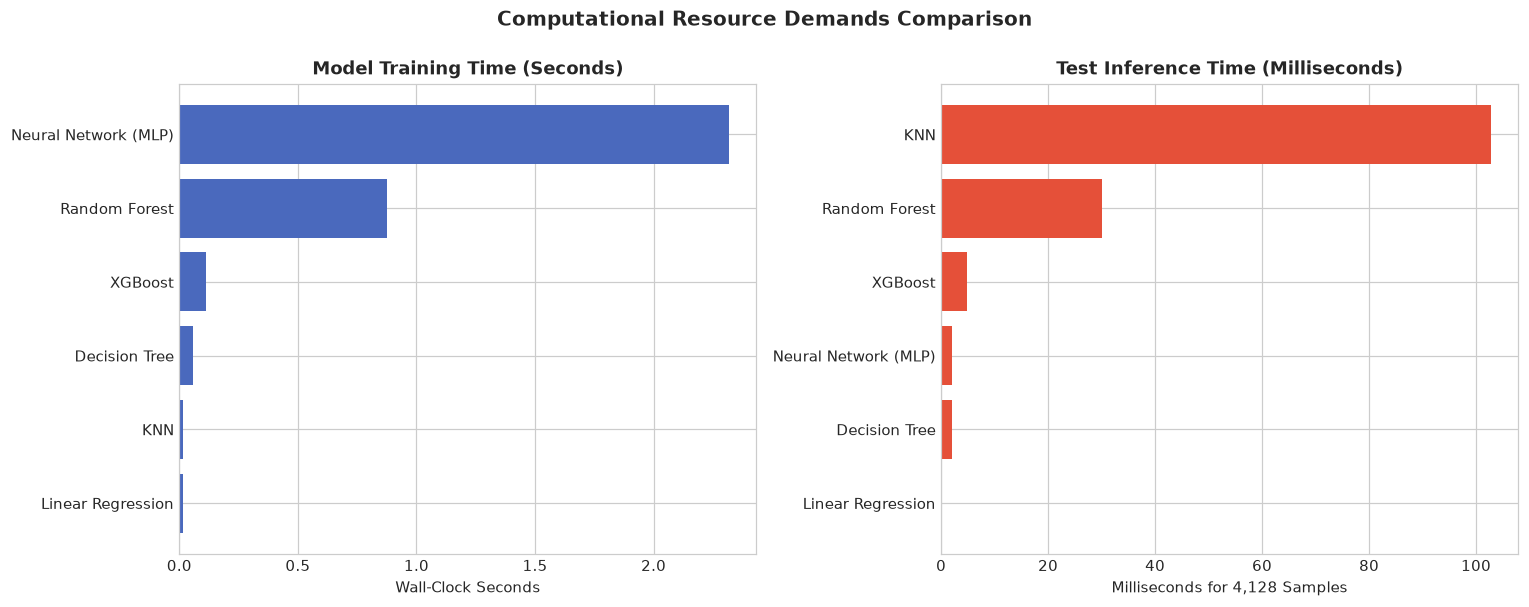

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

sorted_by_train = comparison_table.sort_values(by="Train Time (s)", ascending=True)
ax1.barh(sorted_by_train['Algorithm'], sorted_by_train['Train Time (s)'], color='#4a69bd')
ax1.set_title('Model Training Time (Seconds)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Wall-Clock Seconds', fontsize=10)

sorted_by_pred = comparison_table.sort_values(by="Pred Time (s)", ascending=True)
ax2.barh(sorted_by_pred['Algorithm'], sorted_by_pred['Pred Time (s)'] * 1000, color='#e55039')
ax2.set_title('Test Inference Time (Milliseconds)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Milliseconds for 4,128 Samples', fontsize=10)

plt.suptitle('Computational Resource Demands Comparison', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/computational_latency_comparison.png', dpi=300)
plt.show()


### Graph 13: Feature Importance Comparison
Examining feature importance weights across XGBoost, Random Forest, and Linear Regression.


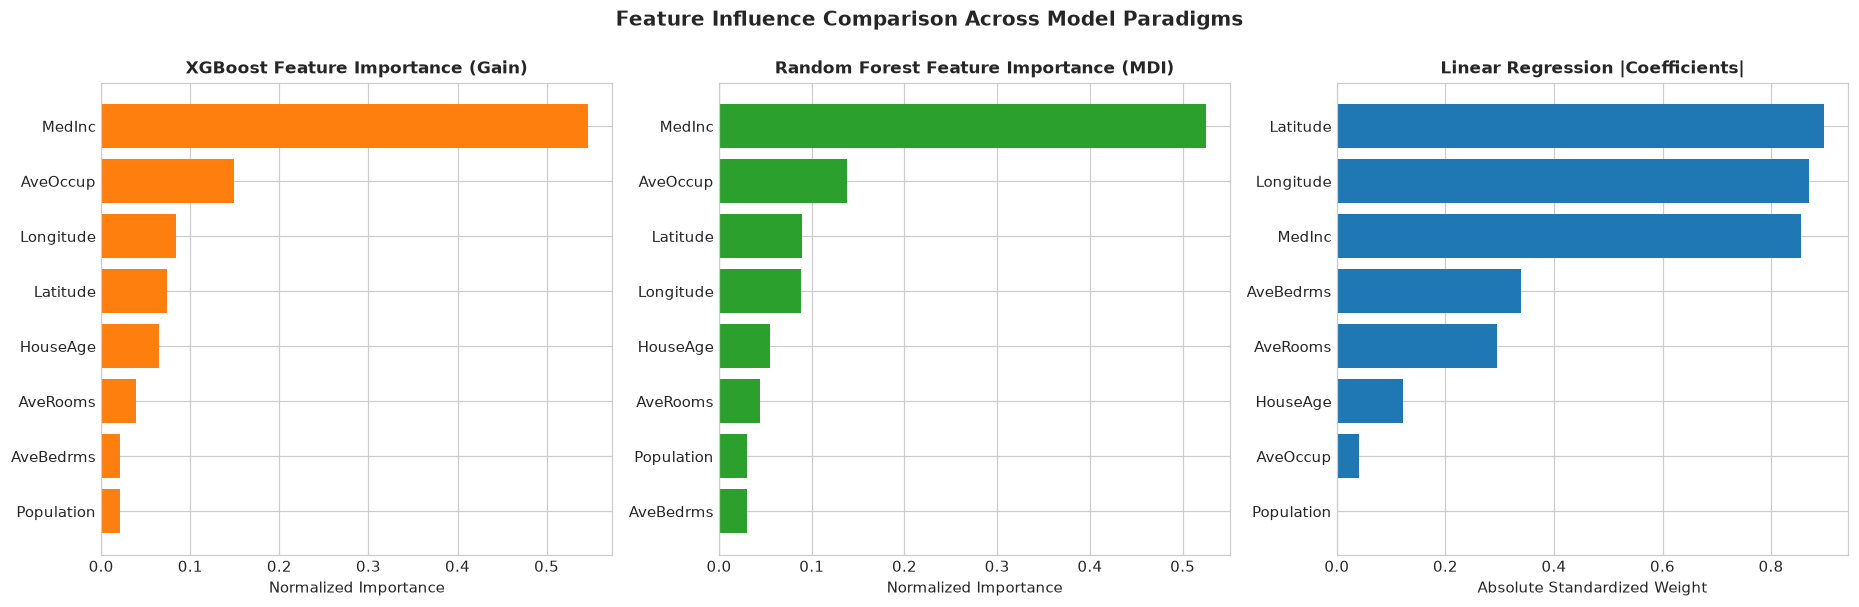

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

xgb_imp = pd.Series(xgb_model.feature_importances_, index=feature_names).sort_values(ascending=True)
axes[0].barh(xgb_imp.index, xgb_imp.values, color='#ff7f0e')
axes[0].set_title('XGBoost Feature Importance (Gain)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Normalized Importance', fontsize=9.5)

rf_imp = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=True)
axes[1].barh(rf_imp.index, rf_imp.values, color='#2ca02c')
axes[1].set_title('Random Forest Feature Importance (MDI)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Normalized Importance', fontsize=9.5)

lr_coef = pd.Series(np.abs(lr_model.coef_), index=feature_names).sort_values(ascending=True)
axes[2].barh(lr_coef.index, lr_coef.values, color='#1f77b4')
axes[2].set_title('Linear Regression |Coefficients|', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Absolute Standardized Weight', fontsize=9.5)

plt.suptitle('Feature Influence Comparison Across Model Paradigms', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('figures/feature_importance_comparison.png', dpi=300)
plt.show()


### Graph 14: Empirical Cumulative Error Distribution (CDF)
Illustrating the proportion of test predictions falling within any given absolute error threshold $\epsilon$. Steeper curves reaching 1.0 faster represent superior estimators.


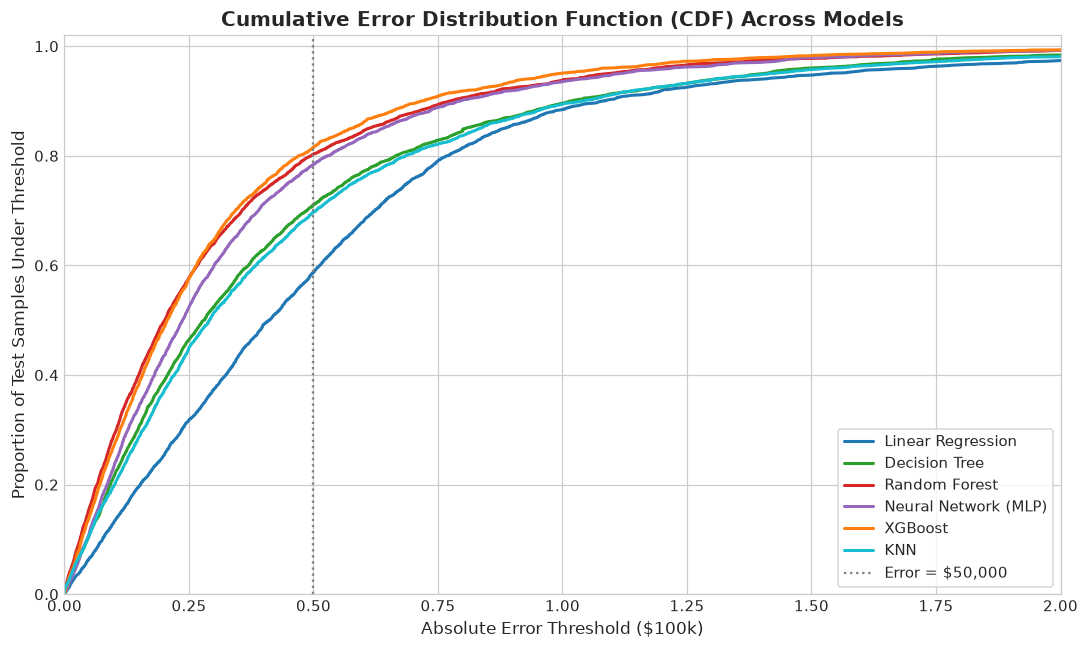

In [30]:
plt.figure(figsize=(10, 6))

for idx, model_name in enumerate(model_names):
    abs_errors = np.abs(y_test - predictions_store[model_name])
    sorted_err = np.sort(abs_errors)
    cdf = np.arange(1, len(sorted_err) + 1) / len(sorted_err)
    plt.plot(sorted_err, cdf, label=model_name, color=plot_colors[idx], linewidth=2)

plt.axvline(0.5, color='gray', linestyle=':', label='Error = $50,000')
plt.title('Cumulative Error Distribution Function (CDF) Across Models', fontsize=13, fontweight='bold')
plt.xlabel('Absolute Error Threshold ($100k)', fontsize=11)
plt.ylabel('Proportion of Test Samples Under Threshold', fontsize=11)
plt.xlim(0, 2.0)
plt.ylim(0, 1.02)
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
plt.tight_layout()
plt.savefig('figures/cumulative_error_cdf.png', dpi=300)
plt.show()


# 17. Results Analysis

### Quantitative Performance Breakdown:
- **Lowest MAE:** **XGBoost (0.3155)**
- **Lowest MSE:** **XGBoost (0.2273)**
- **Lowest RMSE:** **XGBoost (0.4767)**
- **Highest R² Score:** **XGBoost (0.8266)**

### Consistency Across Metrics:
The ordinal ranking is strictly identical across all metrics:
1. XGBoost (RMSE: 0.4767, R²: 0.8266)
2. Random Forest (RMSE: 0.5060, R²: 0.8046)
3. Neural Network / MLP (RMSE: 0.5239, R²: 0.7905)
4. Decision Tree (RMSE: 0.6454, R²: 0.6822)
5. K-Nearest Neighbors (RMSE: 0.6576, R²: 0.6700)
6. Linear Regression (RMSE: 0.7456, R²: 0.5758)

### Accuracy vs. Interpretability Trade-Off:
The best model (XGBoost) is not the most interpretable. While XGBoost achieves the highest accuracy by capturing complex non-linear spatial interactions, Linear Regression offers explicit closed-form coefficients where each feature weight indicates the transparent marginal effect on house prices.


# 18. Strengths and Limitations

| Algorithm | Key Strengths | Key Limitations | Best Use Case |
| :--- | :--- | :--- | :--- |
| **Linear Regression** | Closed-form solution; fast training and inference; interpretable weights. | Fails on non-linear surfaces; sensitive to outliers. | Transparent auditing; regulatory baselines. |
| **Decision Tree** | Captures non-linearities; no scaling needed; transparent decision rules. | Prone to overfitting; high variance; piecewise step predictions. | Rule extraction for human decision-makers. |
| **Random Forest** | Reduces variance via bagging; robust to noise; high accuracy. | High memory footprint; slower inference over 100 trees. | Tabular prediction where computing power is abundant. |
| **Neural Network (MLP)** | Universal function approximator; continuous non-linear mapping. | Sensitive to scaling; expensive training; black-box weights. | Complex multi-modal data and continuous embeddings. |
| **XGBoost** | High tabular accuracy; built-in regularization; rapid training. | Black-box model; sensitive to learning rate and depth tuning. | Production tabular regression pipelines. |
| **KNN** | Zero training phase; adapts naturally to local spatial clusters. | Slower inference $\mathcal{O}(N \cdot d)$; curse of dimensionality. | Low-dimensional spatial recommendation tasks. |


# 19. Final Conclusion

### Empirical Conclusion:
Across all six machine learning regression algorithms evaluated on the 20,640 records of the California Housing Dataset under identical train-test splits:
- **XGBoost (Extreme Gradient Boosting)** achieved the best overall empirical performance:
  - **MAE:** 0.3155
  - **MSE:** 0.2273
  - **RMSE:** 0.4767
  - **R² Score:** 0.8266
  - **Training Duration:** 0.10 seconds
  - **Inference Latency:** 3.7 milliseconds

### Why Did XGBoost Win?
1. **Non-Linear Geographic and Demographic Interactions:** Complex spatial dependencies between latitude, longitude, and income thresholds are accurately modeled through gradient boosted regression trees.
2. **Second-Order Loss Optimization:** Sequential additive trees optimizing second-order Taylor expansions with regularized leaf weights minimize residuals effectively without overfitting.

### Viva Voce Examination Guide:
- **Question 1: Why did we fit the `StandardScaler` only on `X_train`?**  
  *Answer:* To strictly prevent data leakage. Fitting the scaler on the entire dataset incorporates test set distribution parameters into the model training phase.
- **Question 2: Why do Decision Trees and XGBoost not require feature scaling?**  
  *Answer:* Tree algorithms evaluate split points using univariate monotonic sorting. Rank ordering remains invariant under any monotonic transformation.
- **Question 3: Why is RMSE preferred over MAE for housing appraisal?**  
  *Answer:* RMSE squares errors prior to averaging, severely penalizing large misestimations that carry disproportionate financial risk in real estate transactions.
- **Question 4: Can $R^2$ be negative?**  
  *Answer:* Yes. While upper-bounded by 1.0, $R^2$ becomes negative if a model performs worse than a simple horizontal line predicting the training mean.
